In [1]:
#import the pandas library to read a CSV file
import pandas as pd
#import the numpy library to create a numpy array
import numpy as np

In [2]:
data = pd.read_csv('C:/Users/pc/Downloads/hypertension_data.csv')

In [3]:
data

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,57.0,1.0,3,145,233,1,0,150,0,2.3,0,0,1,1
1,64.0,0.0,2,130,250,0,1,187,0,3.5,0,0,2,1
2,52.0,1.0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56.0,0.0,1,120,236,0,1,178,0,0.8,2,0,2,1
4,66.0,0.0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26078,72.0,0.0,0,138,294,1,1,106,0,1.9,1,3,2,0
26079,60.0,1.0,0,144,200,0,0,126,1,0.9,1,0,3,0
26080,68.0,1.0,0,100,234,0,1,156,0,0.1,2,1,3,0
26081,67.0,1.0,1,154,232,0,0,164,0,0.0,2,1,2,0


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26083 entries, 0 to 26082
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       26083 non-null  float64
 1   sex       26058 non-null  float64
 2   cp        26083 non-null  int64  
 3   trestbps  26083 non-null  int64  
 4   chol      26083 non-null  int64  
 5   fbs       26083 non-null  int64  
 6   restecg   26083 non-null  int64  
 7   thalach   26083 non-null  int64  
 8   exang     26083 non-null  int64  
 9   oldpeak   26083 non-null  float64
 10  slope     26083 non-null  int64  
 11  ca        26083 non-null  int64  
 12  thal      26083 non-null  int64  
 13  target    26083 non-null  int64  
dtypes: float64(3), int64(11)
memory usage: 2.8 MB


In [5]:
# Check for NaN (Not a Number) values in your DataFrame
data.isnull().sum()

age          0
sex         25
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalach      0
exang        0
oldpeak      0
slope        0
ca           0
thal         0
target       0
dtype: int64

In [6]:
# Handle NaN values (Drop rows with NaN)
data.dropna(inplace=True)

In [7]:
data.drop(['slope','chol','oldpeak','ca','thal'], axis =1, inplace=True)

In [8]:
data = data.rename(columns={'age': 'Age', 'cp' : 'ChestPain' , 'sex': 'Sex', 'trestbps': 'RestingBP','fbs': 'FastingBS', 'restecg': 'RestingECG', 'thalach': 'MaxHR', 'exang': 'ExerciseAngina', 'target': 'hypertensivepatient'})

In [9]:
data

,Age,Sex,ChestPain,RestingBP,FastingBS,RestingECG,MaxHR,ExerciseAngina,hypertensivepatient
0,57.0,1.0,3,145,1,0,150,0,1
1,64.0,0.0,2,130,0,1,187,0,1
2,52.0,1.0,1,130,0,0,172,0,1
3,56.0,0.0,1,120,0,1,178,0,1
4,66.0,0.0,0,120,0,1,163,1,1
...,...,...,...,...,...,...,...,...,...
26078,72.0,0.0,0,138,1,1,106,0,0
26079,60.0,1.0,0,144,0,0,126,1,0
26080,68.0,1.0,0,100,0,1,156,0,0
26081,67.0,1.0,1,154,0,0,164,0,0


In [10]:
data['ChestPain'] = data['ChestPain'].apply(lambda x: 0 if x == 0 else 1)

In [11]:
data

,Age,Sex,ChestPain,RestingBP,FastingBS,RestingECG,MaxHR,ExerciseAngina,hypertensivepatient
0,57.0,1.0,1,145,1,0,150,0,1
1,64.0,0.0,1,130,0,1,187,0,1
2,52.0,1.0,1,130,0,0,172,0,1
3,56.0,0.0,1,120,0,1,178,0,1
4,66.0,0.0,0,120,0,1,163,1,1
...,...,...,...,...,...,...,...,...,...
26078,72.0,0.0,0,138,1,1,106,0,0
26079,60.0,1.0,0,144,0,0,126,1,0
26080,68.0,1.0,0,100,0,1,156,0,0
26081,67.0,1.0,1,154,0,0,164,0,0


In [12]:
# Now df includes your target variable
data.to_csv('blood pressure.csv', index=False)

In [13]:
#create two variables, X (features) and y (target)
X = data[['Age', 'Sex','ChestPain','FastingBS','RestingECG','MaxHR','ExerciseAngina','hypertensivepatient']]
y = data['RestingBP']

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.datasets import make_regression
import tensorflow as tf


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\pc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\pc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\traitlets\config\application.py", line 1075, in launch_insta

AttributeError: _ARRAY_API not found

In [15]:
X_train, y_train = make_regression(n_samples=100, n_features=10, noise=0.1)
X_test, y_test = make_regression(n_samples=20, n_features=10, noise=0.1)

In [16]:
#split your data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
model=RandomForestRegressor()

In [18]:
#train your linear regression model on your training data
model.fit(X_train, y_train)

RandomForestRegressor()

In [19]:
#make predictions on your test data
y_pred = model.predict(X_test)

In [20]:
#compare these predictions (y_pred) to the actual values (y_test)
from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse}")
print(f"Root Mean Squared Error: {rmse}")
print(f"R-squared: {r2}")

Mean Squared Error: 74.05832766669185
Root Mean Squared Error: 8.605714826014854
R-squared: 0.7656968613766593


In [21]:
new_data = {
    'Age': 64.0,
    'Sex': 0.0,
    'ChestPain': 1,
    'FastingBS':0,
    'RestingECG': 1,
    'MaxHR': 187,
    'ExerciseAngina': 0,
    'hypertensivepatient': 1,
}

# Creating a DataFrame from the new data (assuming you have pandas imported as pd)
new_df = pd.DataFrame([new_data])

# Making predictions using the pre-trained model
predicted_value = model.predict(new_df)

print(f"Predicted value: {predicted_value[0]}")

Predicted value: 129.9


In [22]:
new_data = {
    'Age': 67.0,
    'Sex': 1.0,
    'ChestPain':1,
    'FastingBS':0,
    'RestingECG': 0,
    'MaxHR': 164,
    'ExerciseAngina': 0,
    'hypertensivepatient': 0,
}

# Creating a DataFrame from the new data (assuming you have pandas imported as pd)
new_df = pd.DataFrame([new_data])

# Making predictions using the pre-trained model
predicted_value = model.predict(new_df)

print(f"Predicted value: {predicted_value[0]}")

Predicted value: 154.0


In [23]:
new_data = {
    'Age': 72.0,
    'Sex': 0.0,
    'ChestPain': 0,
    'FastingBS':1,
    'RestingECG': 1,
    'MaxHR': 106,
    'ExerciseAngina': 0,
    'hypertensivepatient': 0,
}

# Creating a DataFrame from the new data (assuming you have pandas imported as pd)
new_df = pd.DataFrame([new_data])

# Making predictions using the pre-trained model
predicted_value = model.predict(new_df)

print(f"Predicted value: {predicted_value[0]}")

Predicted value: 138.0


In [24]:
new_data = {
    'Age': 55.0,
    'Sex': 0.0,
    'ChestPain': 0,
    'FastingBS':0,
    'RestingECG': 0,
    'MaxHR': 110,
    'ExerciseAngina': 0,
    'hypertensivepatient': 0,
}

# Creating a DataFrame from the new data (assuming you have pandas imported as pd)
new_df = pd.DataFrame([new_data])

# Making predictions using the pre-trained model
predicted_value = model.predict(new_df)

print(f"Predicted value: {predicted_value[0]}")

Predicted value: 130.0


In [25]:
#function categorizing blood pressure
def blood_pressure_category(predicted_value):
    if   predicted_value < 90 and predicted_value >= 60: 
        print('PA Hypotension')
    elif predicted_value < 120 and predicted_value >= 90: 
        print('PA optimale')
    elif predicted_value < 130 and predicted_value >= 120:
        print('PA normale')
    elif predicted_value < 140 and predicted_value >= 130:
        print('PA normale Haute')
    else:
        print('PA Hypertension')
        if predicted_value < 159 and predicted_value >= 140:
            print('GRADE 1')
        elif predicted_value < 179 and predicted_value >= 160:
            print('GRADE 2')
        elif predicted_value >= 180:
            print('GRADE 3')

In [26]:
blood_pressure_category(predicted_value)

PA normale Haute


In [27]:
from tensorflow import keras
from tensorflow.keras import layers # type: ignore

In [28]:
# Create a simple neural network in TensorFlow using selected features
tf_model = keras.Sequential([
    layers.Input(shape=(8,)),  # Adjust input shape based on your features
    layers.Dense(100, activation='relu'),
    layers.Dense(1)  # Adjust output units based on your model
])

In [29]:
# Compile the model
tf_model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])


In [30]:
# Train the model
tf_model.fit(X_train, y_train, epochs=10, batch_size=32)


Epoch 1/10
652/652 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 4744.6880 - mae: 49.4613
Epoch 2/10
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 576.2925 - mae: 18.9405
Epoch 3/10
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 534.6017 - mae: 18.2674
Epoch 4/10
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 502.1939 - mae: 17.6567
Epoch 5/10
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 481.6375 - mae: 17.4006
Epoch 6/10
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 982us/step - loss: 487.0726 - mae: 17.4527
Epoch 7/10
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 466.9052 - mae: 17.0843
Epoch 8/10
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 465.7952 - mae: 17.0456
Epoch 9/10
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 462.9971 - mae: 17.0505
Epoch 10/10
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 947us/step - loss: 449.1773 - mae: 16.7946


In [31]:
# Make predictions using the Random Forest Regressor and TensorFlow model
rf_prediction = model.predict(new_df)
tf_prediction = tf_model.predict(new_df)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


In [32]:
# Compare predictions 
print(f"Random Forest Prediction: {rf_prediction}")
print(f"TensorFlow Prediction: {tf_prediction}")

Random Forest Prediction: [130.]
TensorFlow Prediction: [[100.007]]


In [33]:
# Use Random Forest prediction only
best_prediction = rf_prediction
best_model = "Random Forest"

print(f"\nBest Prediction: {best_prediction} (from {best_model})")



Best Prediction: [130.] (from Random Forest)


In [34]:
# Categorize blood pressure based on the best prediction
blood_pressure_category(best_prediction)

PA normale Haute


In [35]:
# Convert the TensorFlow model to TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(tf_model)
tflite_model = converter.convert()

INFO:tensorflow:Assets written to: C:\Users\pc\AppData\Local\Temp\tmpdldlffof\assets


INFO:tensorflow:Assets written to: C:\Users\pc\AppData\Local\Temp\tmpdldlffof\assets


Saved artifact at 'C:\Users\pc\AppData\Local\Temp\tmpdldlffof'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 8), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2485979317264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2485963013008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2485979316880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2485979316496: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [36]:
import pickle
with open("hypertension.pickle","wb") as f : 
  pickle.dump(model,f)
  

In [37]:
with open("hypertension.pickle","rb") as f : 
  model = pickle.load(f)

In [38]:
# Save the TFLite model to a file
#with open('hypertension.tflite', 'wb') as f:
    #f.write(tflite_model)

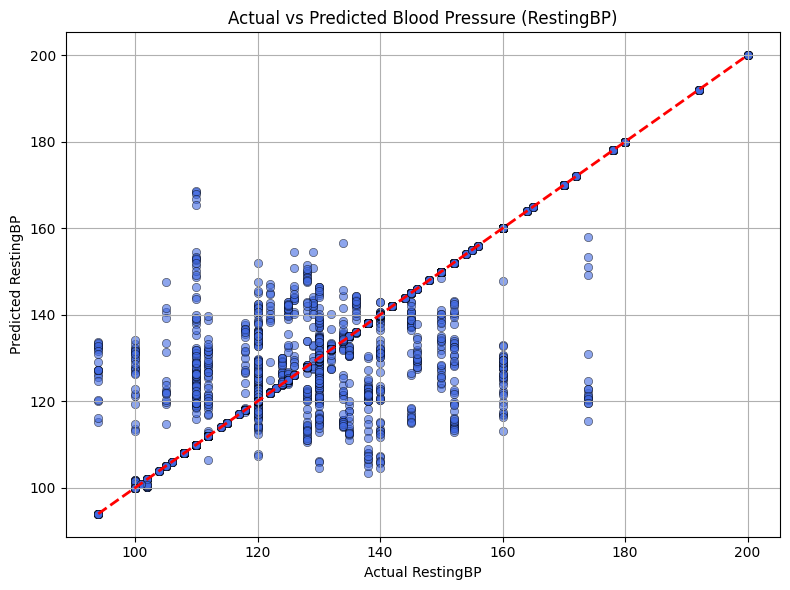

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import seaborn as sns


# Plotting: Actual vs Predicted
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color='royalblue', edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual RestingBP")
plt.ylabel("Predicted RestingBP")
plt.title("Actual vs Predicted Blood Pressure (RestingBP)")
plt.grid(True)
plt.tight_layout()
plt.show()


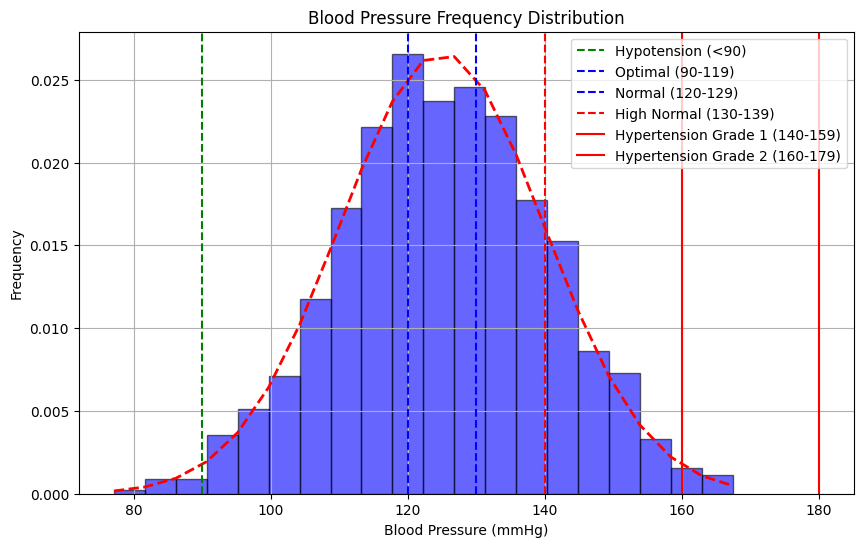

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Simulate blood pressure data (replace with actual predictions)
mu, sigma = 125, 15 # mean and standard deviation
bp_predictions = np.random.normal(mu, sigma, 1000)

# Create histogram
plt.figure(figsize=(10,6))
n, bins, patches = plt.hist(bp_predictions, bins=20, density=True, 
                           alpha=0.6, color='b', edgecolor='black')

# Add normal distribution curve
y = norm.pdf(bins, mu, sigma)
plt.plot(bins, y, 'r--', linewidth=2)

# Add categorization lines and labels
plt.axvline(x=90, color='g', linestyle='--', label='Hypotension (<90)')
plt.axvline(x=120, color='b', linestyle='--', label='Optimal (90-119)')
plt.axvline(x=130, color='b', linestyle='--', label='Normal (120-129)')
plt.axvline(x=140, color='r', linestyle='--', label='High Normal (130-139)')
plt.axvline(x=160, color='r', linestyle='-', label='Hypertension Grade 1 (140-159)')
plt.axvline(x=180, color='r', linestyle='-', label='Hypertension Grade 2 (160-179)')

plt.title('Blood Pressure Frequency Distribution')
plt.xlabel('Blood Pressure (mmHg)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.show()

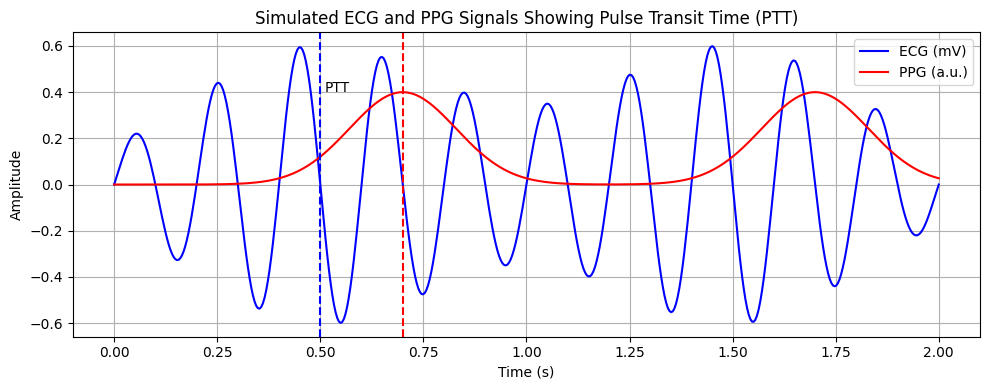

In [45]:
import numpy as np
import matplotlib.pyplot as plt

# Time vector
t = np.linspace(0, 2, 500)  # 2 seconds duration

# Simulated ECG signal (R-peaks at 0.5s and 1.5s)
ecg = 0.6 * np.sin(2 * np.pi * 5 * t) * np.exp(-5 * (t - 0.5)**2) \
    + 0.6 * np.sin(2 * np.pi * 5 * t) * np.exp(-5 * (t - 1.5)**2)

# Simulated PPG signal delayed from ECG (PTT)
ptt_delay = 0.2  # seconds
ppg = 0.4 * np.exp(-30 * (t - 0.7)**2) + 0.4 * np.exp(-30 * (t - 1.7)**2)

# Plotting
plt.figure(figsize=(10, 4))
plt.plot(t, ecg, label='ECG (mV)', color='blue')
plt.plot(t, ppg, label='PPG (a.u.)', color='red')
plt.axvline(x=0.5, linestyle='--', color='blue')
plt.axvline(x=0.7, linestyle='--', color='red')
plt.text(0.51, 0.4, 'PTT', fontsize=10, color='black')

# Additional annotations
plt.title('Simulated ECG and PPG Signals Showing Pulse Transit Time (PTT)')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend(loc='upper right')
plt.grid(True)
plt.tight_layout()
plt.show()